In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.21.0
Keras: 3.13.2


In [2]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

possible_roots = [Path("."), Path(".."), Path("../..")]

PROJECT_ROOT = None
for root in possible_roots:
    if (root / "data" / "deepsmote").exists():
        PROJECT_ROOT = root.resolve()
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError("Não foi possível localizar data/deepsmote.")

DATA_DIR = PROJECT_ROOT / "data"
DEEPSMOTE_DIR = DATA_DIR / "deepsmote"
MODELS_DIR = PROJECT_ROOT / "models" / "deep_smote"

TRAIN_REAL_CSV = DEEPSMOTE_DIR / "train_real_split.csv"
TEST_REAL_CSV = DEEPSMOTE_DIR / "test_real_split.csv"
SYNTH_CSV = DEEPSMOTE_DIR / "metadata_deepsmote.csv"

MODEL_PATH = MODELS_DIR / "best_densenet169_deepsmote_saved_images.keras"

IMG_SIZE = (320, 320)
BATCH_SIZE = 16
EVALUATE_TRAIN_WITH_SYNTHETIC = False

classes = ["MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC"]
class_name = {idx: label for idx, label in enumerate(classes)}

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DEEPSMOTE_DIR:", DEEPSMOTE_DIR)
print("MODEL_PATH:", MODEL_PATH)

PROJECT_ROOT: /Users/alexandre/Documents/GitHub/skin-cancer-classification
DEEPSMOTE_DIR: /Users/alexandre/Documents/GitHub/skin-cancer-classification/data/deepsmote
MODEL_PATH: /Users/alexandre/Documents/GitHub/skin-cancer-classification/models/best_densenet169_deepsmote_saved_images.keras


In [3]:
for path in [TRAIN_REAL_CSV, TEST_REAL_CSV, MODEL_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {path}")

train_real_df = pd.read_csv(TRAIN_REAL_CSV)
test_df = pd.read_csv(TEST_REAL_CSV)

if EVALUATE_TRAIN_WITH_SYNTHETIC and SYNTH_CSV.exists():
    synth_df = pd.read_csv(SYNTH_CSV)
    train_df = pd.concat([train_real_df, synth_df], ignore_index=True)
    print("Treino usado: train_real_split.csv + metadata_deepsmote.csv")
    print("Treino real:", len(train_real_df))
    print("Sintéticas:", len(synth_df))
else:
    train_df = train_real_df.copy()
    print("Treino usado: apenas train_real_split.csv")

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nTotal treino:", len(train_df))
print("Total teste:", len(test_df))

print("\nDistribuição treino:")
print(train_df["class_name"].value_counts().reindex(classes))

print("\nDistribuição teste:")
print(test_df["class_name"].value_counts().reindex(classes))

display(train_df.head())
display(test_df.head())

Treino usado: apenas train_real_split.csv

Total treino: 8012
Total teste: 2003

Distribuição treino:
class_name
MEL       890
NV       5364
BCC       411
AKIEC     262
BKL       879
DF         92
VASC      114
Name: count, dtype: int64

Distribuição teste:
class_name
MEL       223
NV       1341
BCC       103
AKIEC      65
BKL       220
DF         23
VASC       28
Name: count, dtype: int64


,image,image_path,mask_path,class_name,label,is_synthetic
0,ISIC_0031747,../../data/images/ISIC_0031747.jpg,../../data/masks/ISIC_0031747_segmentation.png,NV,1,0
1,ISIC_0027507,../../data/images/ISIC_0027507.jpg,../../data/masks/ISIC_0027507_segmentation.png,MEL,0,0
2,ISIC_0031146,../../data/images/ISIC_0031146.jpg,../../data/masks/ISIC_0031146_segmentation.png,MEL,0,0
3,ISIC_0027413,../../data/images/ISIC_0027413.jpg,../../data/masks/ISIC_0027413_segmentation.png,NV,1,0
4,ISIC_0028104,../../data/images/ISIC_0028104.jpg,../../data/masks/ISIC_0028104_segmentation.png,BKL,4,0


,image,image_path,mask_path,class_name,label,is_synthetic
0,ISIC_0030663,../../data/images/ISIC_0030663.jpg,../../data/masks/ISIC_0030663_segmentation.png,NV,1,0
1,ISIC_0031269,../../data/images/ISIC_0031269.jpg,../../data/masks/ISIC_0031269_segmentation.png,NV,1,0
2,ISIC_0027885,../../data/images/ISIC_0027885.jpg,../../data/masks/ISIC_0027885_segmentation.png,NV,1,0
3,ISIC_0028348,../../data/images/ISIC_0028348.jpg,../../data/masks/ISIC_0028348_segmentation.png,NV,1,0
4,ISIC_0032177,../../data/images/ISIC_0032177.jpg,../../data/masks/ISIC_0032177_segmentation.png,NV,1,0


In [4]:
def resolve_path_from_csv(path_value):
    if pd.isna(path_value):
        return None

    raw = Path(str(path_value))
    candidates = [
        raw,
        PROJECT_ROOT / raw,
        DEEPSMOTE_DIR / raw,
        DATA_DIR / "images" / raw.name,
    ]

    # Para imagens sintéticas salvas em subpastas por classe.
    candidates.extend(list((DEEPSMOTE_DIR / "images").glob(f"**/{raw.name}")))

    for candidate in candidates:
        if candidate.exists():
            return str(candidate.resolve())

    return str(raw)


def prepare_dataframe_paths(df):
    df = df.copy()

    if "image_path" not in df.columns:
        raise ValueError("O CSV precisa ter a coluna image_path.")

    if "label" not in df.columns:
        raise ValueError("O CSV precisa ter a coluna label.")

    if "class_name" not in df.columns:
        df["class_name"] = df["label"].map(class_name)

    df["resolved_image_path"] = df["image_path"].apply(resolve_path_from_csv)

    missing = [
        path for path in df["resolved_image_path"].values
        if not Path(str(path)).exists()
    ]

    print("Total:", len(df))
    print("Caminhos não encontrados:", len(missing))

    if missing:
        print("\nExemplos de caminhos não encontrados:")
        for item in missing[:10]:
            print(item)
        raise FileNotFoundError("Há caminhos de imagens nos CSVs que não foram encontrados.")

    return df


train_df = prepare_dataframe_paths(train_df)
test_df = prepare_dataframe_paths(test_df)

print("Caminhos resolvidos com sucesso.")

Total: 8012
Caminhos não encontrados: 0
Total: 2003
Caminhos não encontrados: 0
Caminhos resolvidos com sucesso.


In [5]:
def load_image_tf(image_path, label):
    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label


def build_image_dataset(df, batch_size=BATCH_SIZE):
    image_paths = df["resolved_image_path"].astype(str).values
    labels = df["label"].astype("int32").values

    ds = tf.data.Dataset.from_tensor_slices((image_paths, labels))
    ds = ds.map(load_image_tf, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


train_ds = build_image_dataset(train_df)
test_ds = build_image_dataset(test_df)

y_train = train_df["label"].astype("int32").values
y_test = test_df["label"].astype("int32").values

print("train_ds criado a partir dos CSVs.")
print("test_ds criado a partir dos CSVs.")
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

train_ds criado a partir dos CSVs.
test_ds criado a partir dos CSVs.
y_train: (8012,)
y_test: (2003,)


In [6]:
# Patch de compatibilidade para BatchNormalization antiga.
from keras.layers import BatchNormalization

_original_batchnorm_init = BatchNormalization.__init__

def _patched_batchnorm_init(self, *args, **kwargs):
    kwargs.pop("renorm", None)
    kwargs.pop("renorm_clipping", None)
    kwargs.pop("renorm_momentum", None)
    _original_batchnorm_init(self, *args, **kwargs)

BatchNormalization.__init__ = _patched_batchnorm_init

model = keras.models.load_model(
    MODEL_PATH,
    compile=False,
    safe_mode=False
)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "densenet169_deepsmote_saved_images"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 320, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 320, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add (Add)                       │ (None, 320, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 320, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet169 (Functional)        │ (None, 10, 10, 1664)   │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1664)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       852,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,631,559 (52.00 MB)

 Trainable params: 987,143 (3.77 MB)

 Non-trainable params: 12,644,416 (48.23 MB)

In [7]:
start_time = time.time()

train_loss, train_accuracy = model.evaluate(train_ds, verbose=1)
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

elapsed_time = time.time() - start_time

print("\nRESULTADOS DE LOSS E ACURÁCIA")
print(f"Train Loss: {train_loss:.4f}")
print(f"Train Accuracy: {train_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Tempo de avaliação: {elapsed_time:.2f} segundos")

501/501 ━━━━━━━━━━━━━━━━━━━━ 437s 867ms/step - accuracy: 0.9406 - loss: 0.2100
126/126 ━━━━━━━━━━━━━━━━━━━━ 153s 1s/step - accuracy: 0.8108 - loss: 0.6018

RESULTADOS DE LOSS E ACURÁCIA
Train Loss: 0.2100
Train Accuracy: 0.9406
Test Loss: 0.6018
Test Accuracy: 0.8108
Tempo de avaliação: 590.12 segundos


In [8]:
start_time = time.time()

train_pred_probs = model.predict(train_ds, verbose=1)
test_pred_probs = model.predict(test_ds, verbose=1)

y_train_pred = np.argmax(train_pred_probs, axis=1)
y_test_pred = np.argmax(test_pred_probs, axis=1)

elapsed_time = time.time() - start_time

print("Predições geradas.")
print("train_pred_probs:", train_pred_probs.shape)
print("test_pred_probs:", test_pred_probs.shape)
print(f"Tempo de predição: {elapsed_time:.2f} segundos")

501/501 ━━━━━━━━━━━━━━━━━━━━ 619s 1s/step
126/126 ━━━━━━━━━━━━━━━━━━━━ 166s 1s/step
Predições geradas.
train_pred_probs: (8012, 7)
test_pred_probs: (2003, 7)
Tempo de predição: 785.69 segundos


In [9]:
def print_metrics(y_true, y_pred, loss_value, dataset_name):
    print(f"Relatório de Classificação - {dataset_name.upper()}:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=classes,
        digits=4,
        zero_division=0
    ))

    acc = accuracy_score(y_true, y_pred)

    macro_precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
    macro_recall = recall_score(y_true, y_pred, average="macro", zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    weighted_precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    weighted_recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    print(f"\nMÉTRICAS GERAIS DO MODELO - {dataset_name.upper()}")
    print(f"Loss: {loss_value:.4f}")
    print(f"Accuracy: {acc:.4f}")

    print("\nMacro Average:")
    print(f"  Precision: {macro_precision:.4f}")
    print(f"  Recall: {macro_recall:.4f}")
    print(f"  F1-score: {macro_f1:.4f}")

    print("\nWeighted Average:")
    print(f"  Precision: {weighted_precision:.4f}")
    print(f"  Recall: {weighted_recall:.4f}")
    print(f"  F1-score: {weighted_f1:.4f}")

    return {
        "dataset": dataset_name,
        "loss": loss_value,
        "accuracy": acc,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "weighted_precision": weighted_precision,
        "weighted_recall": weighted_recall,
        "weighted_f1": weighted_f1
    }


train_metrics = print_metrics(y_train, y_train_pred, train_loss, "Treino")
test_metrics = print_metrics(y_test, y_test_pred, test_loss, "Teste")

metrics_comparison_df = pd.DataFrame([train_metrics, test_metrics])
display(metrics_comparison_df)

Relatório de Classificação - TREINO:
              precision    recall  f1-score   support

         MEL     0.8570    0.7742    0.8135       890
          NV     0.9629    0.9817    0.9722      5364
         BCC     0.9085    0.9416    0.9247       411
       AKIEC     0.8872    0.8702    0.8786       262
         BKL     0.8985    0.8760    0.8871       879
          DF     0.9880    0.8913    0.9371        92
        VASC     0.9828    1.0000    0.9913       114

    accuracy                         0.9406      8012
   macro avg     0.9264    0.9050    0.9149      8012
weighted avg     0.9394    0.9406    0.9396      8012


MÉTRICAS GERAIS DO MODELO - TREINO
Loss: 0.2100
Accuracy: 0.9406

Macro Average:
  Precision: 0.9264
  Recall: 0.9050
  F1-score: 0.9149

Weighted Average:
  Precision: 0.9394
  Recall: 0.9406
  F1-score: 0.9396
Relatório de Classificação - TESTE:
              precision    recall  f1-score   support

         MEL     0.5404    0.4798    0.5083       223
        

,dataset,loss,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
0,Treino,0.210019,0.940589,0.926379,0.905003,0.914937,0.939353,0.940589,0.939613
1,Teste,0.601835,0.810784,0.681825,0.618706,0.639800,0.802262,0.810784,0.804916


In [12]:
print("Relatório de Classificação - TESTE:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=classes,
    digits=4,
    zero_division=0
))

test_acc = accuracy_score(y_test, y_test_pred)

test_macro_precision = precision_score(
    y_test,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_macro_recall = recall_score(
    y_test,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_macro_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_weighted_precision = precision_score(
    y_test,
    y_test_pred,
    average="weighted",
    zero_division=0
)

test_weighted_recall = recall_score(
    y_test,
    y_test_pred,
    average="weighted",
    zero_division=0
)

test_weighted_f1 = f1_score(
    y_test,
    y_test_pred,
    average="weighted",
    zero_division=0
)

print("\nMÉTRICAS GERAIS DO MODELO - TESTE")
print(f"Loss: {test_loss:.4f}")
print(f"Accuracy: {test_acc:.4f}")

print("\nMacro Average:")
print(f"  Precision: {test_macro_precision:.4f}")
print(f"  Recall: {test_macro_recall:.4f}")
print(f"  F1-score: {test_macro_f1:.4f}")

print("\nWeighted Average:")
print(f"  Precision: {test_weighted_precision:.4f}")
print(f"  Recall: {test_weighted_recall:.4f}")
print(f"  F1-score: {test_weighted_f1:.4f}")

test_metrics_df = pd.DataFrame([{
    "dataset": "Teste",
    "loss": test_loss,
    "accuracy": test_acc,
    "macro_precision": test_macro_precision,
    "macro_recall": test_macro_recall,
    "macro_f1": test_macro_f1,
    "weighted_precision": test_weighted_precision,
    "weighted_recall": test_weighted_recall,
    "weighted_f1": test_weighted_f1
}])

display(test_metrics_df)

Relatório de Classificação - TESTE:
              precision    recall  f1-score   support

         MEL     0.5404    0.4798    0.5083       223
          NV     0.9001    0.9403    0.9198      1341
         BCC     0.6000    0.6408    0.6197       103
       AKIEC     0.5246    0.4923    0.5079        65
         BKL     0.6528    0.5727    0.6102       220
          DF     0.7273    0.3478    0.4706        23
        VASC     0.8276    0.8571    0.8421        28

    accuracy                         0.8108      2003
   macro avg     0.6818    0.6187    0.6398      2003
weighted avg     0.8023    0.8108    0.8049      2003


MÉTRICAS GERAIS DO MODELO - TESTE
Loss: 0.6018
Accuracy: 0.8108

Macro Average:
  Precision: 0.6818
  Recall: 0.6187
  F1-score: 0.6398

Weighted Average:
  Precision: 0.8023
  Recall: 0.8108
  F1-score: 0.8049


,dataset,loss,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
0,Teste,0.601835,0.810784,0.681825,0.618706,0.6398,0.802262,0.810784,0.804916


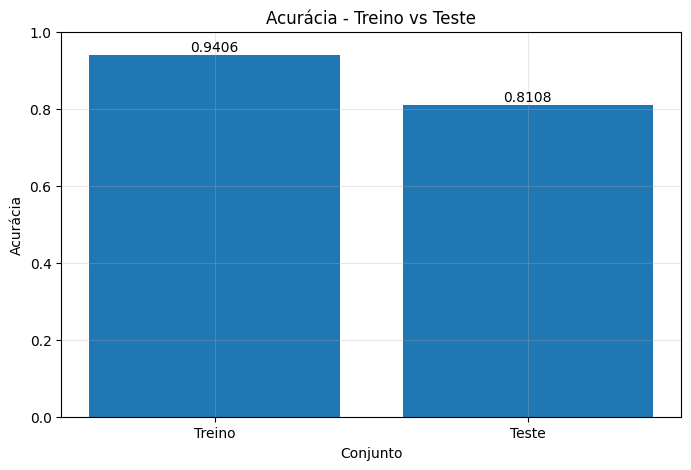

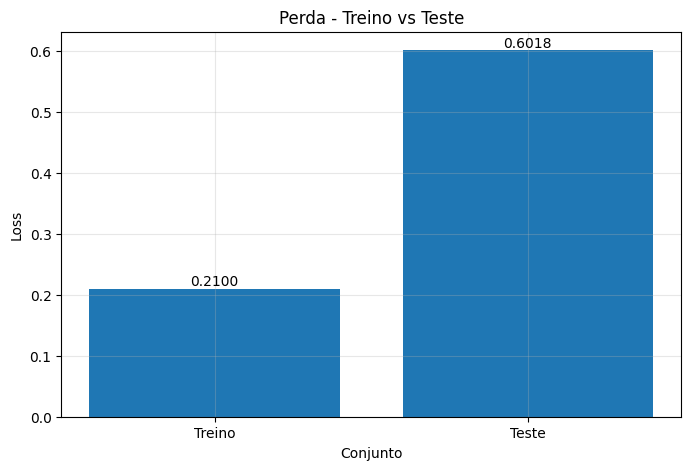

In [10]:
plt.figure(figsize=(8, 5))
plt.bar(metrics_comparison_df["dataset"], metrics_comparison_df["accuracy"])
plt.title("Acurácia - Treino vs Teste")
plt.xlabel("Conjunto")
plt.ylabel("Acurácia")
plt.ylim(0, 1)

for i, value in enumerate(metrics_comparison_df["accuracy"]):
    plt.text(i, value, f"{value:.4f}", ha="center", va="bottom")

plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(metrics_comparison_df["dataset"], metrics_comparison_df["loss"])
plt.title("Perda - Treino vs Teste")
plt.xlabel("Conjunto")
plt.ylabel("Loss")

for i, value in enumerate(metrics_comparison_df["loss"]):
    plt.text(i, value, f"{value:.4f}", ha="center", va="bottom")

plt.grid(True, alpha=0.3)
plt.show()

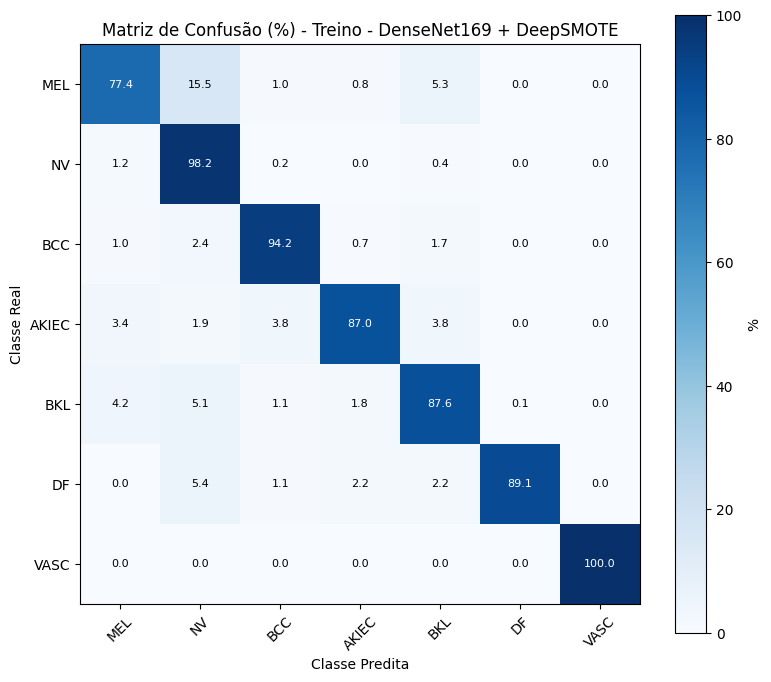

,MEL,NV,BCC,AKIEC,BKL,DF,VASC
MEL,77.415730,15.505618,1.011236,0.786517,5.280899,0.000000,0.000000
NV,1.211782,98.173005,0.167785,0.018643,0.391499,0.000000,0.037286
BCC,0.973236,2.433090,94.160584,0.729927,1.703163,0.000000,0.000000
AKIEC,3.435115,1.908397,3.816794,87.022901,3.816794,0.000000,0.000000
BKL,4.209329,5.119454,1.137656,1.820250,87.599545,0.113766,0.000000
DF,0.000000,5.434783,1.086957,2.173913,2.173913,89.130435,0.000000
VASC,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.000000


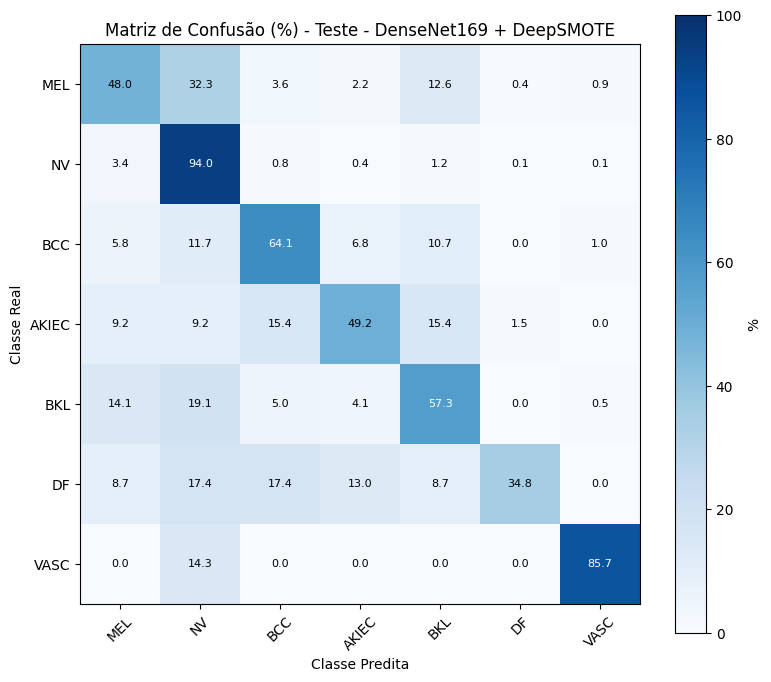

,MEL,NV,BCC,AKIEC,BKL,DF,VASC
MEL,47.982063,32.286996,3.587444,2.242152,12.556054,0.448430,0.896861
NV,3.430276,94.034303,0.820283,0.372856,1.193139,0.074571,0.074571
BCC,5.825243,11.650485,64.077670,6.796117,10.679612,0.000000,0.970874
AKIEC,9.230769,9.230769,15.384615,49.230769,15.384615,1.538462,0.000000
BKL,14.090909,19.090909,5.000000,4.090909,57.272727,0.000000,0.454545
DF,8.695652,17.391304,17.391304,13.043478,8.695652,34.782609,0.000000
VASC,0.000000,14.285714,0.000000,0.000000,0.000000,0.000000,85.714286


In [11]:
def plot_confusion_percent(y_true, y_pred, title):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(len(classes)))
    )

    cm_percent = cm.astype("float") / cm.sum(axis=1, keepdims=True) * 100
    cm_percent = np.nan_to_num(cm_percent)

    plt.figure(figsize=(8, 7))
    im = plt.imshow(
        cm_percent,
        interpolation="nearest",
        cmap="Blues",
        vmin=0,
        vmax=100
    )

    plt.title(title)
    plt.colorbar(im, label="%")

    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    for i in range(cm_percent.shape[0]):
        for j in range(cm_percent.shape[1]):
            color = "white" if cm_percent[i, j] > 50 else "black"
            plt.text(
                j,
                i,
                f"{cm_percent[i, j]:.1f}",
                ha="center",
                va="center",
                color=color,
                fontsize=8
            )

    plt.ylabel("Classe Real")
    plt.xlabel("Classe Predita")
    plt.tight_layout()
    plt.show()

    cm_df = pd.DataFrame(cm_percent, index=classes, columns=classes)
    display(cm_df)

    return cm_df


cm_train_df = plot_confusion_percent(
    y_train,
    y_train_pred,
    "Matriz de Confusão (%) - Treino - DenseNet169 + DeepSMOTE"
)

cm_test_df = plot_confusion_percent(
    y_test,
    y_test_pred,
    "Matriz de Confusão (%) - Teste - DenseNet169 + DeepSMOTE"
)